# Movie Review Sentiment Analysis Using NLP and Machine Learning



In [1]:
%pip install -q pandas numpy scikit-learn matplotlib joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import html
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
%matplotlib inline


In [3]:
DATA_PATH = "IMDB Dataset.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumn names:", df.columns.tolist())
print("\\nSentiment counts:")
print(df["sentiment"].value_counts(dropna=False))

Dataset shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


\nColumn names: ['review', 'sentiment']
\nSentiment counts:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [4]:
required_columns = {"review", "sentiment"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"CSV is missing required columns: {missing_columns}")

df = df[["review", "sentiment"]].dropna().copy()
df["sentiment"] = df["sentiment"].astype(str).str.strip().str.lower()
df = df[df["sentiment"].isin(["positive", "negative"])]
df = df.drop_duplicates(subset=["review"]).reset_index(drop=True)

print("Clean dataset shape:", df.shape)
display(df["sentiment"].value_counts().to_frame("count"))


Clean dataset shape: (49582, 2)


,count
sentiment,
positive,24884
negative,24698


In [5]:
def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)      
    text = text.lower()
    text = re.sub(r"[^a-z\\s']", " ", text)  
    text = re.sub(r"\\s+", " ", text).strip()
    return text

df["clean_review"] = df["review"].apply(clean_text)

print("Original review:")
print(df.loc[0, "review"][:500])
print("\\nCleaned review:")
print(df.loc[0, "clean_review"][:500])


Original review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ
\nCleaned review:
one of the other reviewers has mentioned that after watching just   oz episode you'll be hooked  they are right  as this is exactly what happened with me   the first thing that struck me about oz was its brutality and unflinching scenes of violence  which set in right from the word go  trust me  this is not a show for the faint hearted or timid  this show pulls no punches with regards to drugs  sex or violence  its is hardcore  in the classic use of the word  

In [6]:
X = df["clean_review"]
y = df["sentiment"].map({"negative": 0, "positive": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))
print("\\nTraining label proportions:")
print(y_train.value_counts(normalize=True))


Training reviews: 39665
Testing reviews: 9917
\nTraining label proportions:
sentiment
1    0.501878
0    0.498122
Name: proportion, dtype: float64


In [7]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

model.fit(X_train, y_train)
print("Training completed.")


Training completed.


In [8]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print("\\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"],
    digits=4
))


Test accuracy: 0.9055 (90.55%)
\nClassification report:
              precision    recall  f1-score   support

    Negative     0.9171    0.8909    0.9038      4940
    Positive     0.8947    0.9200    0.9072      4977

    accuracy                         0.9055      9917
   macro avg     0.9059    0.9055    0.9055      9917
weighted avg     0.9058    0.9055    0.9055      9917



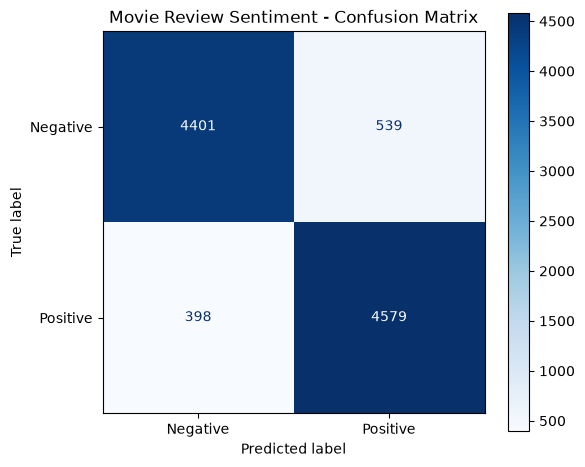

In [9]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)
fig, ax = plt.subplots(figsize=(6, 5))

disp.plot(
    ax=ax,
    values_format="d",
    cmap="Blues"
)

ax.set_title("Movie Review Sentiment - Confusion Matrix")
plt.tight_layout()
plt.show()


Output:


In [10]:
def predict_sentiment(review):
    cleaned_review = clean_text(review)
    prediction = int(model.predict([cleaned_review])[0])
    probabilities = model.predict_proba([cleaned_review])[0]

    label = "Positive" if prediction == 1 else "Negative"
    confidence = float(probabilities[prediction])

    return {
        "review": review,
        "predicted_sentiment": label,
        "confidence": round(confidence, 4)
    }

sample_reviews = [
    "This movie was fantastic. The acting and story were excellent!",
    "The film was boring, poorly written, and a complete waste of time.",
    "I did not expect much, but I really enjoyed this movie."
]

for review in sample_reviews:
    print(predict_sentiment(review))


{'review': 'This movie was fantastic. The acting and story were excellent!', 'predicted_sentiment': 'Positive', 'confidence': 0.8971}
{'review': 'The film was boring, poorly written, and a complete waste of time.', 'predicted_sentiment': 'Negative', 'confidence': 0.9968}
{'review': 'I did not expect much, but I really enjoyed this movie.', 'predicted_sentiment': 'Positive', 'confidence': 0.7964}
